# MoA: configuration, schematic, results and routing

Code: `models/moa/` (module + `__init__.py` builder), configs: `models/moa/configs/*.yaml`.
Deviations from the reference: docs/deviations.md. Variants: docs/variant_registry.md.

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "backbone").exists():        # works from notebooks/ or models/<s>/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from backbone.paths import DATA_ROOT, RUNS_ROOT, FIG_ROOT
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("project:", ROOT); print("data:", DATA_ROOT); print("runs:", RUNS_ROOT)

project: /home/claude/work/MoE_Structures_v2
data: /home/claude/work/MoE_Structures_v2/_data
runs: /home/claude/work/MoE_Structures_v2/runs


In [2]:
from backbone.config import list_variants, load_yaml, variant_path
for v in list_variants("moa"):
    print(f"--- {v}"); print(json.dumps(load_yaml(variant_path("moa", v)).get("structure_params", {})))

--- default
{"num_experts": 8, "k": 4, "gate_norm": "raw", "switchloss": 0.01, "zloss": 0.001}
--- k8
{"num_experts": 8, "k": 8, "gate_norm": "raw", "switchloss": 0.01, "zloss": 0.001}
--- renorm_detached
{"num_experts": 8, "k": 4, "gate_norm": "renorm_detached", "switchloss": 0.01, "zloss": 0.001}


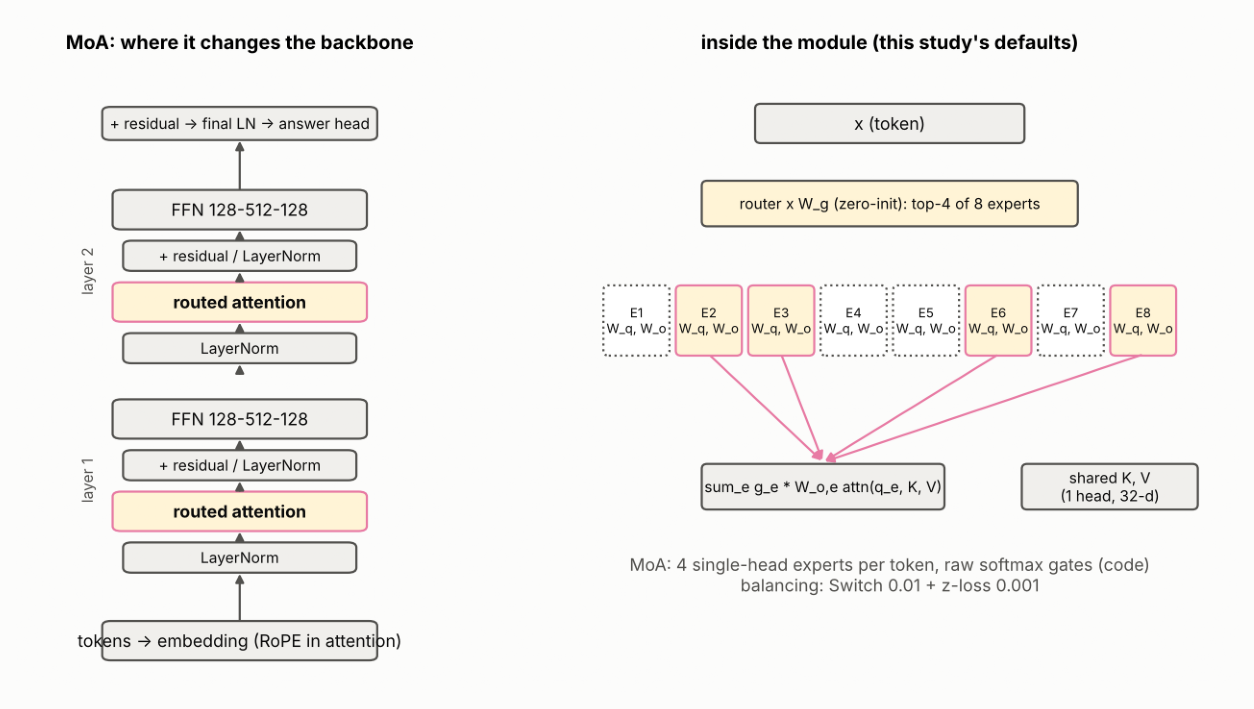

In [3]:
from analysis.schematics import draw
import matplotlib.pyplot as plt, matplotlib.image as mpimg
def show(p, size=(11, 5.5)):
    if p: plt.figure(figsize=size); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.show()
show(draw("moa"))

In [4]:
from analysis.collect import load_results, load_routing, agg
from analysis import figures as F
df = load_results(RUNS_ROOT); d = df[df.structure == "moa"]
if len(d):
    t = agg(d, ["dataset", "variant", "balance"])
    display(t.pivot_table(index=["dataset", "variant"], columns="balance", values="mean").round(3))
else:
    print("no finished runs yet")

balance                     lb   none  warmup
dataset variant                              
copy    default            NaN  1.000     NaN
fact    default          0.457  0.352   0.405
        k8               0.789  0.783   0.785
        renorm_detached  0.204  0.207   0.174
logic   default            NaN  0.548     NaN
mix     default            NaN  0.639     NaN
mod     default          0.168  0.215   0.224
mqar    default            NaN  0.123     NaN
rev     default            NaN  1.000     NaN

entropy  max_load  dead
dataset variant         balance                         
copy    default         none       0.899     0.226   0.0
fact    default         lb         0.986     0.172   0.0
                        none       0.919     0.220   0.0
                        warmup     0.952     0.211   0.0
        k8              lb         1.000     0.125   0.0
                        none       1.000     0.125   0.0
                        warmup     1.000     0.125   0.0
        renorm_detached lb         0.981     0.168   0.0
                        none       0.946     0.212   0.0
                        warmup     0.921     0.222   0.0
logic   default         none       0.773     0.249   2.0
mix     default         none       0.977     0.160   0.0
mod     default         lb         0.988     0.168   0.0
                        none       0.940     0.217   0.0
                        warmup     0.953     0.209   0.0
mqar    default         none       0.850     0.211   0.0
rev     default         none       0.904     0.209   0.0

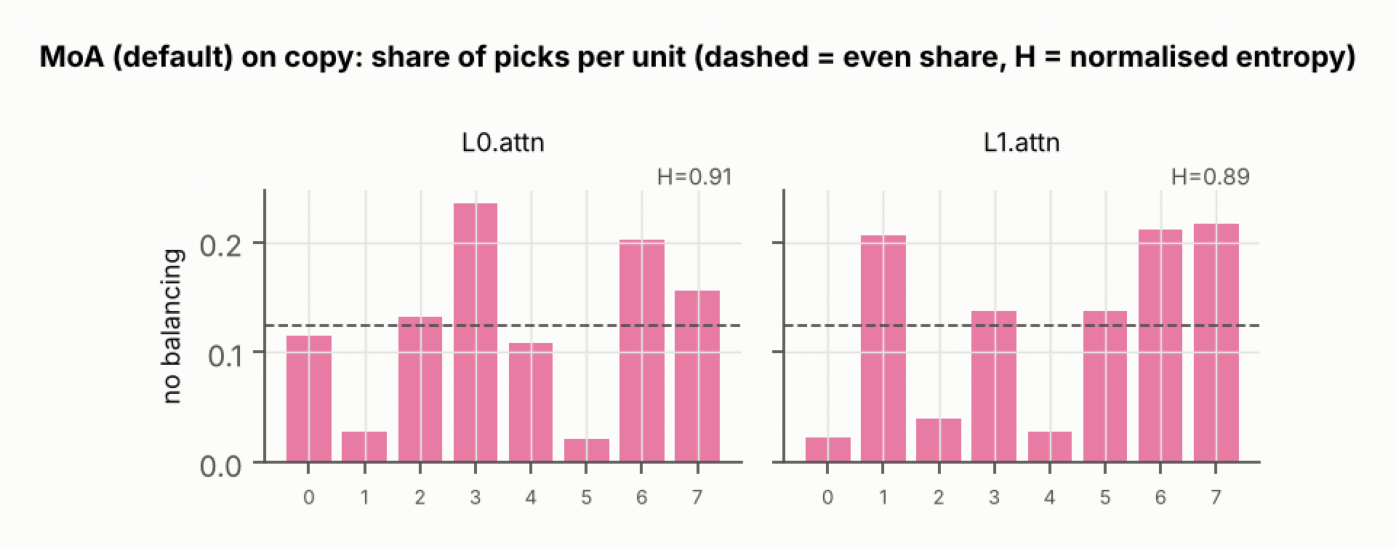

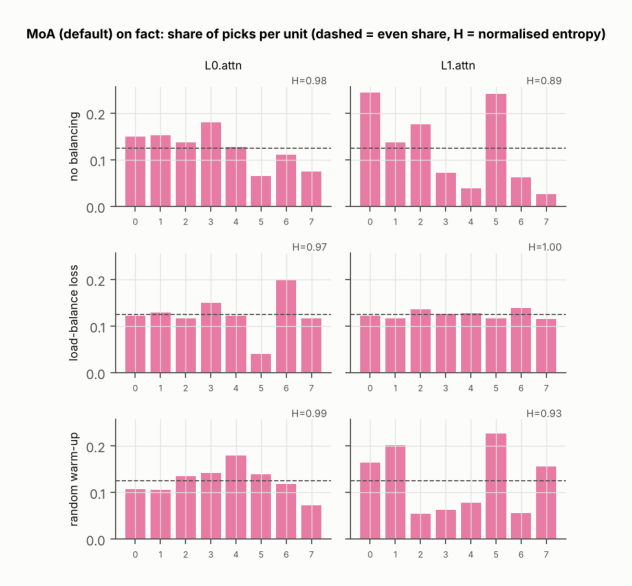

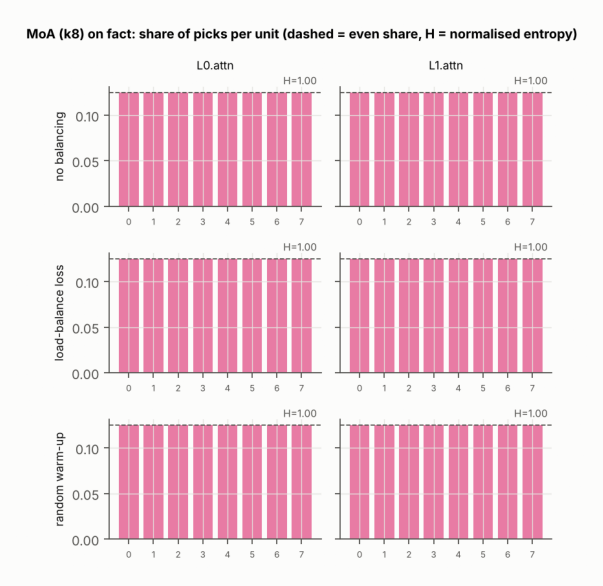

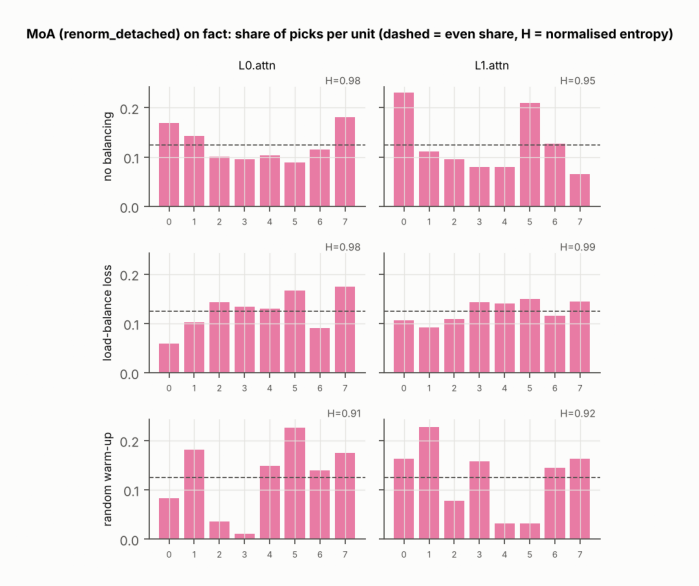

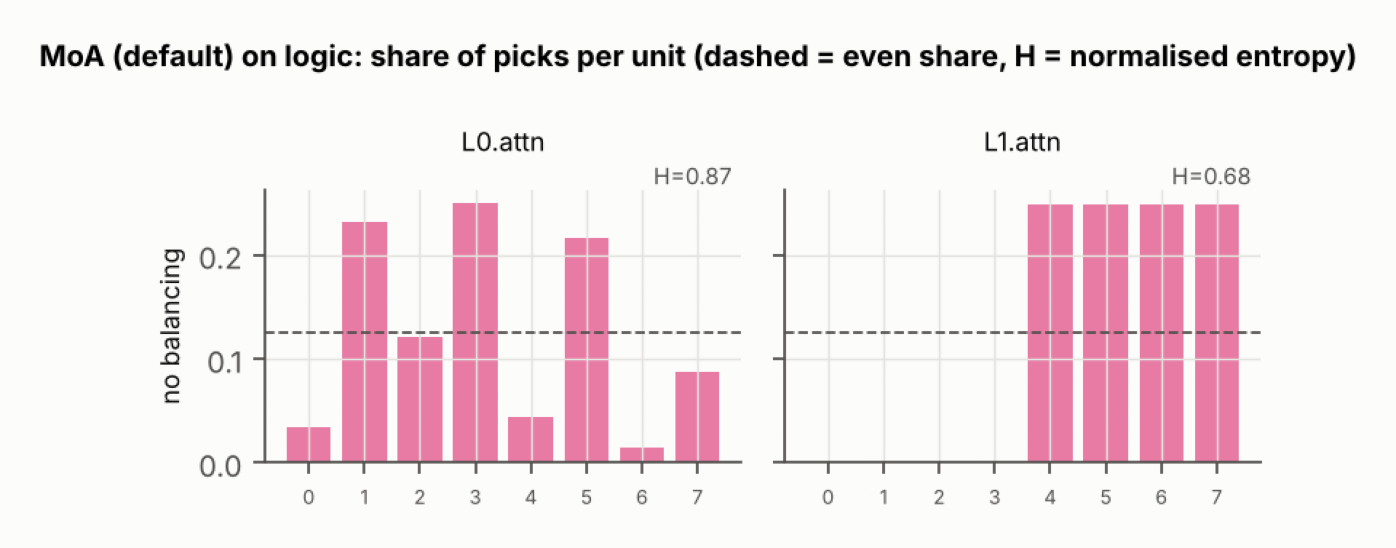

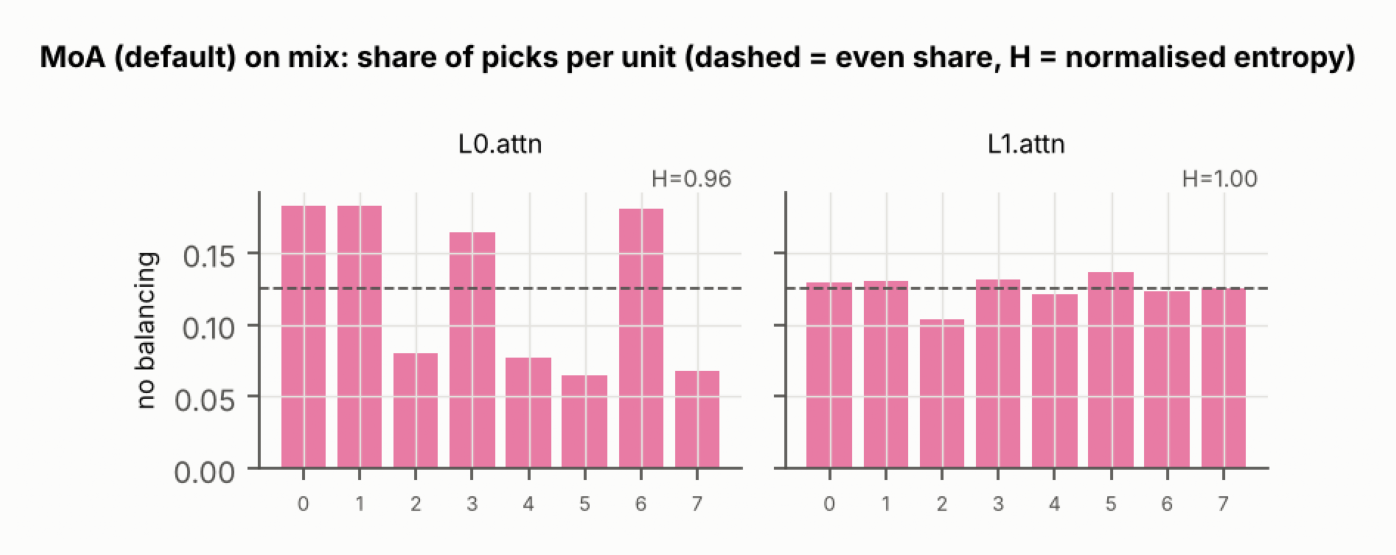

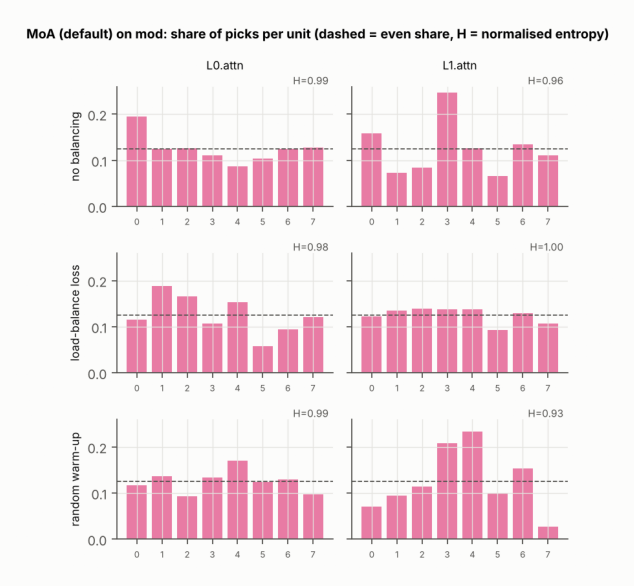

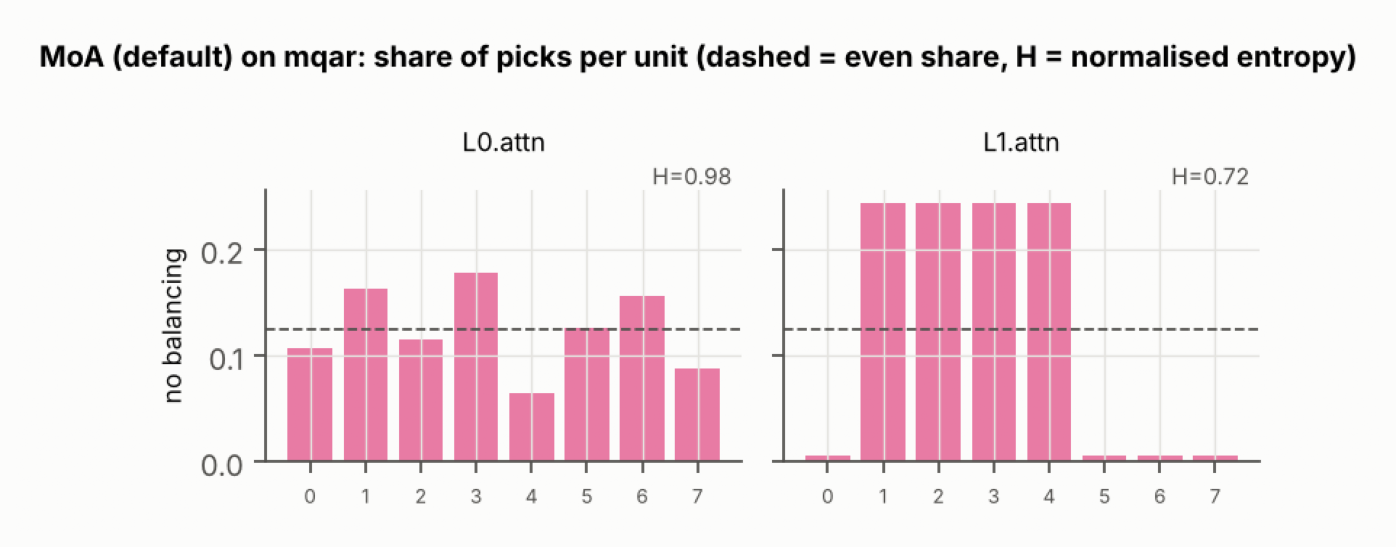

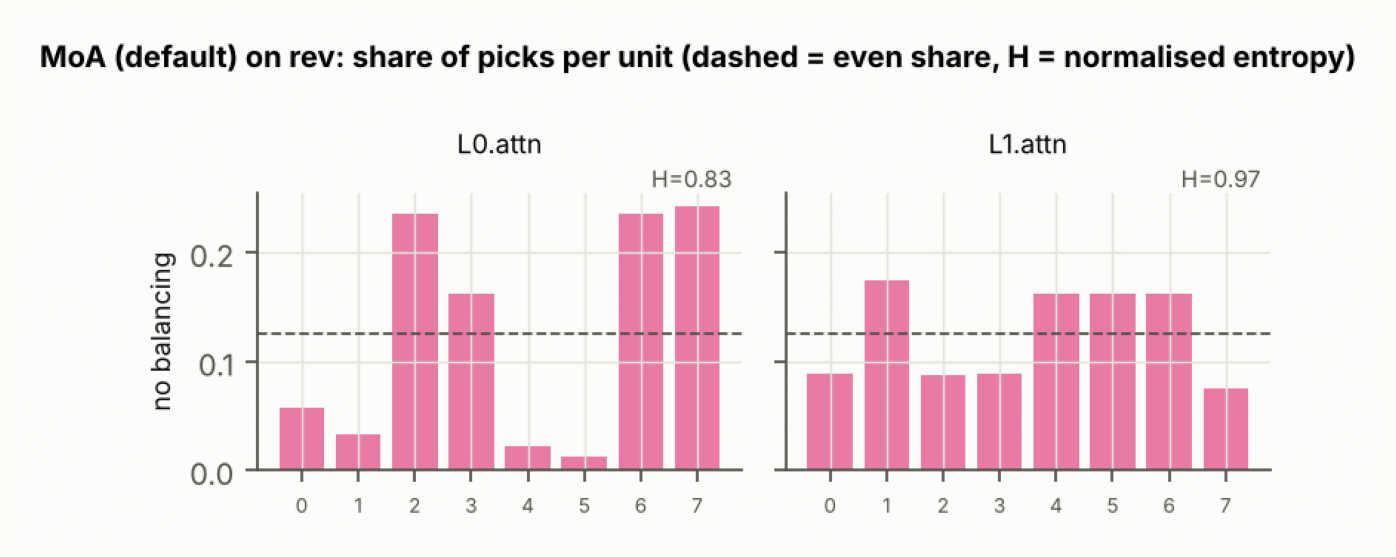

In [5]:
rdf = load_routing(RUNS_ROOT)
if len(rdf) and "moa" in set(rdf.structure):
    r = rdf[rdf.structure == "moa"]
    display(r.groupby(["dataset", "variant", "balance"])[["entropy", "max_load", "dead"]].mean().round(3))
    for ds in sorted(set(r.dataset)):
        for v in sorted(set(r[r.dataset == ds].variant)):
            show(F.routing_load(rdf, ds, "moa", v), (11, 4.5))